# Лабораторная работа № 1
## Задание №1
> Григорьев Никита M3338, Паховский Иван M3339


In [3]:
import random
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

LAMBDA = 1 / 2

X_MU = 1 / LAMBDA
X_SIGMA = 1 / LAMBDA

VAR_X = 1 / (LAMBDA**2)
VAR_SIGMA = np.sqrt(8) / (LAMBDA**2)

QUANTILE_MU = np.log(2) / LAMBDA
QUANTILE_SIGMA = 1 / LAMBDA

K = 12
J = 10


NUM_SAMPLES = 10000

In [4]:
def run(n):
    global X_MU
    global X_SIGMA
    global VAR_X
    global QUANTILE_MU
    global VAR_SIGMA
    global QUANTILE_SIGMA
    global QUANTILE_MU
    global K
    global J

    experiments = []

    for i in range(NUM_SAMPLES):
        experiments.append([np.random.exponential(1 / LAMBDA) for _ in range(n)])

    experiments_variable_mean = []
    experiments_variable_var = []
    experiments_variable_quantile = []
    experiments_variable_quantile_k = []
    experiments_variable_quantile_j = []


    for i in range(NUM_SAMPLES):
        experiments_variable_mean.append(np.mean(experiments[i]))
        experiments_variable_var.append(np.var(experiments[i], ddof=1))
        experiments_variable_quantile.append(np.quantile(experiments[i], 0.5))

        sorted_experiments = sorted(experiments[i])

        F_k = 1 - np.exp(-LAMBDA * sorted_experiments[K - 1])
        experiments_variable_quantile_k.append(F_k)

        F_x_j = np.exp(-LAMBDA * sorted_experiments[n - J])
        experiments_variable_quantile_j.append(F_x_j)

    experiments_variable_mean_norm = []
    experiments_variable_var_norm = []
    experiments_variable_quantile_norm = []
    experiments_variable_quantile_k_norm = []
    experiments_variable_quantile_j_norm = []


    for i in range(NUM_SAMPLES):
        experiments_variable_mean_norm.append(((experiments_variable_mean[i] - X_MU) * np.sqrt(n)))
        experiments_variable_var_norm.append((experiments_variable_var[i] - VAR_X) * np.sqrt(n))
        experiments_variable_quantile_norm.append((experiments_variable_quantile[i] - QUANTILE_MU) * np.sqrt(n))
        experiments_variable_quantile_k_norm.append(n * experiments_variable_quantile_k[i])
        experiments_variable_quantile_j_norm.append(n * experiments_variable_quantile_j[i])



    _, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(1, 5, figsize=(25, 5))
    x = np.linspace(-4 * X_SIGMA, 4 * X_SIGMA, 500)

    ax1.hist(experiments_variable_mean_norm, bins=100, density=True, color="blue", edgecolor="black", alpha=0.6, label="Experimental")
    ax1.plot(x, stats.norm.pdf(x, loc=0, scale=X_SIGMA), color="red", lw=2)
    ax1.set_title(f"Variable mu (n = {n})")
    ax1.set_xlim(-4 * X_SIGMA, 4 * X_SIGMA)
    ax1.legend()

    x = np.linspace(-4 * VAR_SIGMA, 4 * VAR_SIGMA, 500)
    ax2.hist(experiments_variable_var_norm, bins=100, density=True, color="blue", edgecolor="black", alpha=0.6, label="Experimental")
    ax2.plot(x, stats.norm.pdf(x, loc=0, scale=VAR_SIGMA), color="red", lw=2)
    ax2.set_title(f"Variable var (n = {n})")
    ax2.set_xlim(-4 * VAR_SIGMA, 4 * VAR_SIGMA)
    ax2.legend()

    ax3.hist(experiments_variable_quantile_norm, bins=100, density=True, color="blue", edgecolor="black", alpha=0.6, label="Experimental")
    ax3.plot(x, stats.norm.pdf(x, loc=0, scale=QUANTILE_SIGMA), color="red", lw=2)
    ax3.set_title(f"Variable quantile 0.5 (n = {n})")
    ax3.set_xlim(-4 * QUANTILE_SIGMA, 4 * QUANTILE_SIGMA)
    ax3.legend()

    x = np.linspace(stats.gamma.ppf(0.001, a=K), stats.gamma.ppf(0.999, a=K), 500)
    ax4.hist(experiments_variable_quantile_k_norm, bins=100, density=True, color="blue", edgecolor="black", alpha=0.6, label="Experimental")
    ax4.plot(x, stats.gamma.pdf(x, a=K, scale=1), color="red", lw=2)
    ax4.set_title(f"Gamma (k={K}, 1) (n = {n})")
    ax4.legend()


    x = np.linspace(stats.gamma.ppf(0.001, a=J), stats.gamma.ppf(0.999, a=J), 500)
    ax5.hist(experiments_variable_quantile_j_norm, bins=100, density=True, color="blue", edgecolor="black", alpha=0.6, label="Experimental")
    ax5.plot(x, stats.gamma.pdf(x, a=J, scale=1), color="red", lw=2)
    ax5.set_title(f"Gamma (j={J}, 1) (n = {n})")
    ax5.legend()


    plt.show()

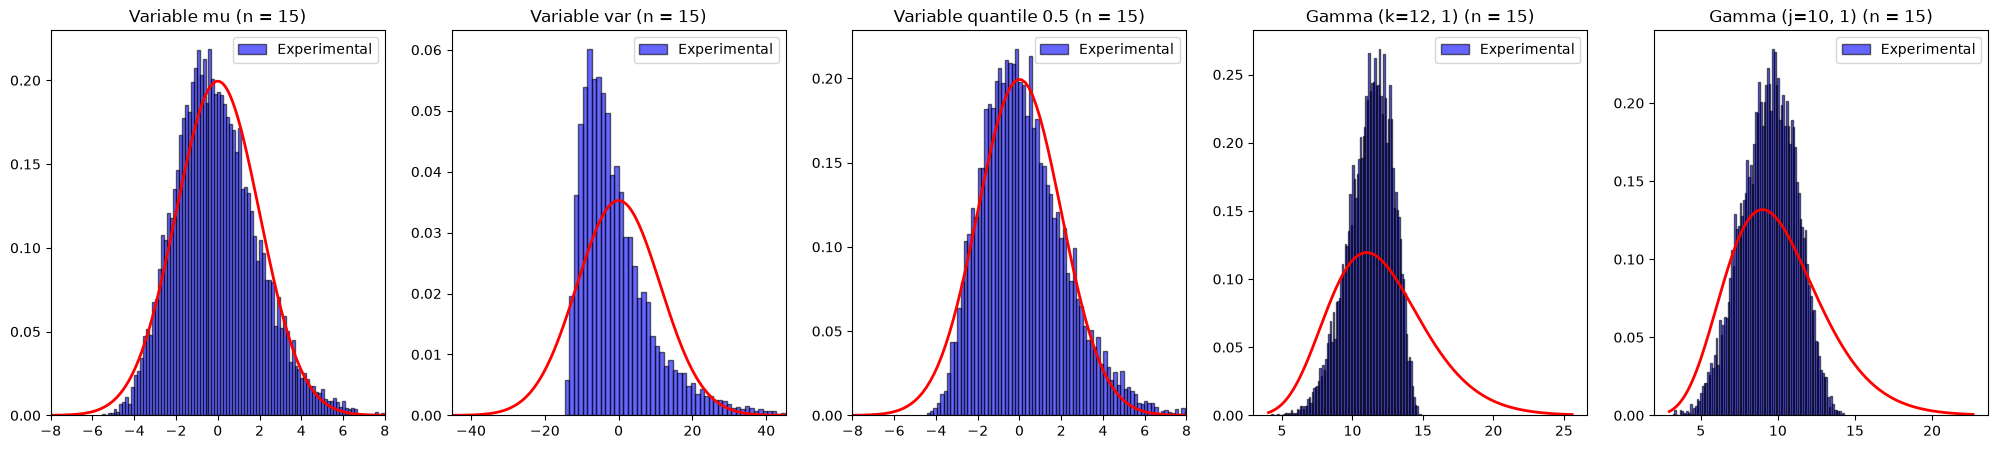

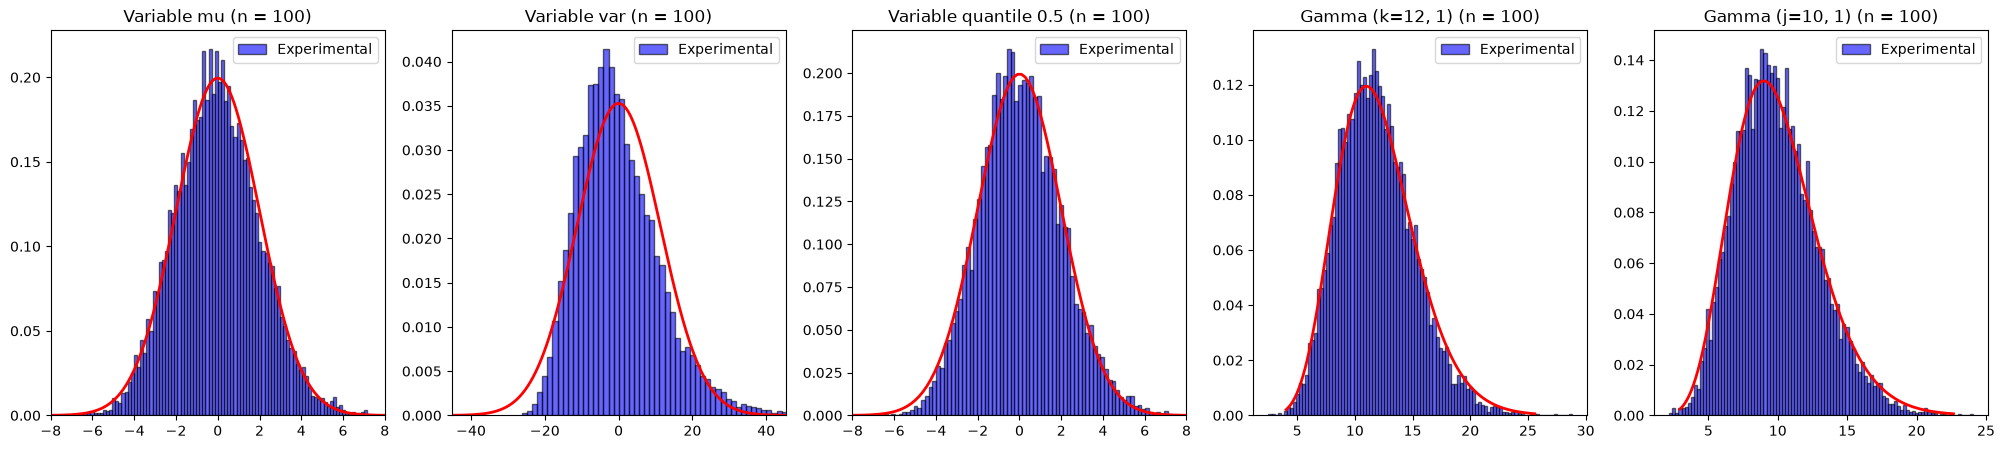

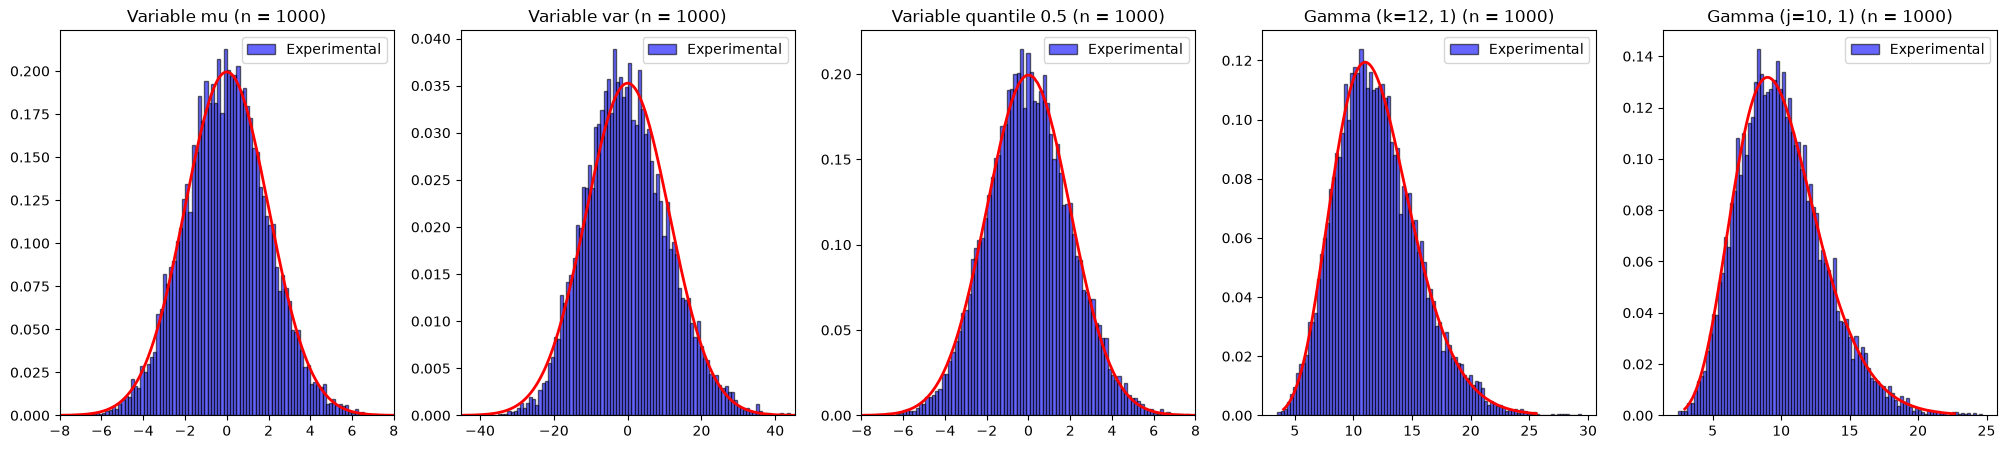

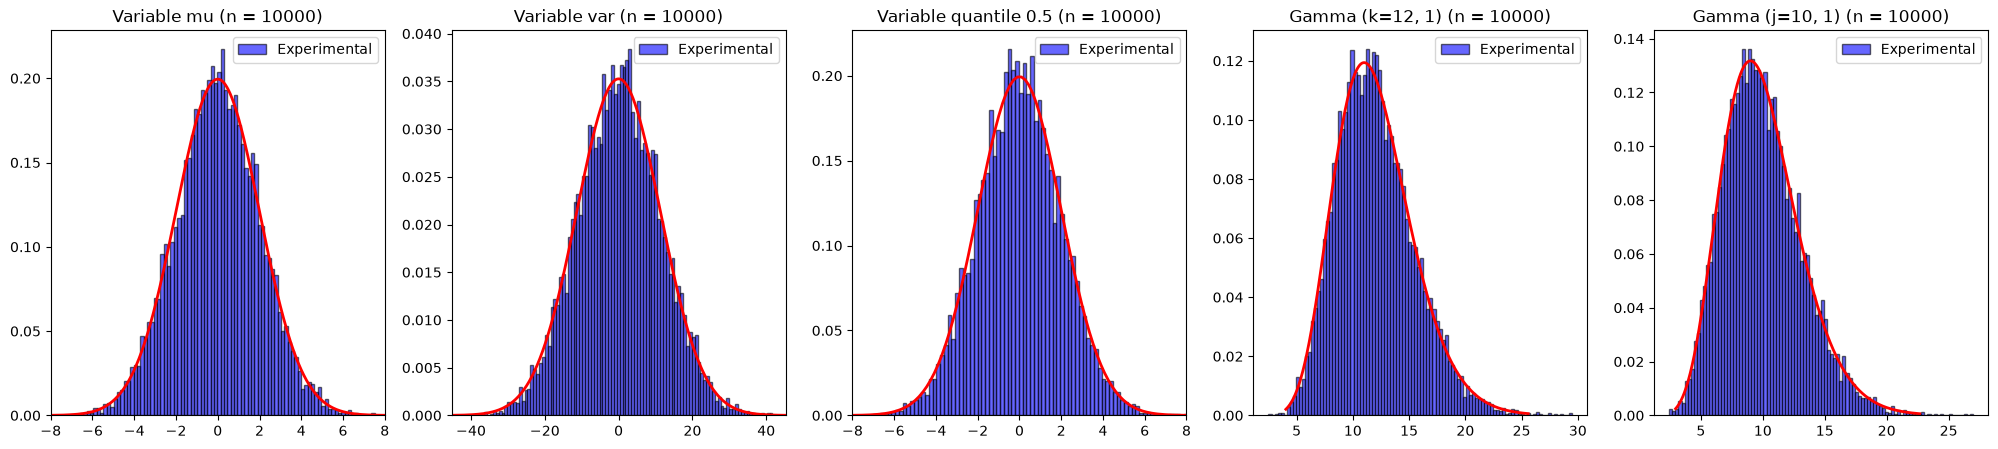

In [5]:
run(15)
run(100)
run(1000)
run(10000)